In [1]:
import pandas as pd
from pathlib import Path

print("Current folder:", Path.cwd())
print("Pandas version:", pd.__version__)

Current folder: c:\Users\boddu\OneDrive\Desktop\data_sales\notebook
Pandas version: 2.2.3


In [4]:
import pandas as pd
from pathlib import Path

# Find the project folder
project_folder = Path.cwd().parent

# Find the CSV file
data_folder = project_folder / "data" / "raw"

csv_files = list(data_folder.glob("Sample - Superstore.csv"))

print("CSV files:", csv_files)

# Load the dataset
df = pd.read_csv(csv_files[0], encoding="cp1252")

print("Dataset loaded successfully!")

CSV files: [WindowsPath('c:/Users/boddu/OneDrive/Desktop/data_sales/data/raw/Sample - Superstore.csv')]
Dataset loaded successfully!


In [5]:
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [8]:
print("Number of rows:",df.columns.tolist())

Number of rows: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [11]:
print("Number of rows:",df.shape[0])
print("Number of rows:",df.shape[1])

Number of rows: 9994
Number of rows: 21


In [24]:
print("sales tabel information:",df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [14]:
missing_values=df.isnull().sum()
print(missing_values[missing_values > 0])

Series([], dtype: int64)


In [15]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [16]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [28]:
df_clean=df.copy()

date_columns=["Order Date","Ship Date"]

for columns in date_columns:
    df_clean[columns]=pd.to_datetime(
        df_clean[columns],
    format="%m/%d/%Y",
        errors="coerce"
)
# Check the results
print(df_clean[date_columns].dtypes)

display(df_clean[date_columns].head())    

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


,Order Date,Ship Date
0,2016-11-08,2016-11-11
1,2016-11-08,2016-11-11
2,2016-06-12,2016-06-16
3,2015-10-11,2015-10-18
4,2015-10-11,2015-10-18


In [32]:
print("invalid date forame:",
      df_clean["Order Date"].isna().sum())

print("Invalid Ship Dates:",
      df_clean["Ship Date"].isna().sum())


invalid date forame: 0
Invalid Ship Dates: 0


In [33]:
# Find orders shipped before they were ordered
invalid_shipping = df_clean[
    df_clean["Ship Date"] < df_clean["Order Date"]
]

print("Invalid shipping records:", len(invalid_shipping))
display(invalid_shipping.head())

Invalid shipping records: 0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit


In [34]:
print("Sales <= 0:", (df_clean["Sales"] <= 0).sum())
print("Quantity <= 0:", (df_clean["Quantity"] <= 0).sum())
print("Profit < 0:", (df_clean["Profit"] < 0).sum())

Sales <= 0: 0
Quantity <= 0: 0
Profit < 0: 1871


In [35]:
print("Unique orders:", df_clean["Order ID"].nunique())
print("Unique customers:", df_clean["Customer ID"].nunique())
print("Unique products:", df_clean["Product ID"].nunique())
print("Unique categories:", df_clean["Category"].nunique())
print("Unique regions:", df_clean["Region"].nunique())

Unique orders: 5009
Unique customers: 793
Unique products: 1862
Unique categories: 3
Unique regions: 4


In [36]:
# Calculate key business metrics

total_sales = df_clean["Sales"].sum()
total_profit = df_clean["Profit"].sum()
total_orders = df_clean["Order ID"].nunique()
total_customers = df_clean["Customer ID"].nunique()
total_products = df_clean["Product ID"].nunique()
average_order_value = total_sales / total_orders

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Unique Products: {total_products:,}")
print(f"Average Sales per Order: ${average_order_value:,.2f}")

Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5,009
Total Customers: 793
Unique Products: 1,862
Average Sales per Order: $458.61


In [37]:
category_sales = (
    df_clean.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

display(category_sales)

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64

In [39]:
region_performance = (
    df_clean.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Order_Count=("Order ID", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(region_performance.round(2))

,Total_Sales,Total_Profit,Order_Count
Region,,,
West,725457.82,108418.45,1611
East,678781.24,91522.78,1401
Central,501239.89,39706.36,1175
South,391721.90,46749.43,822


In [43]:
import matplotlib.pyplot as plt

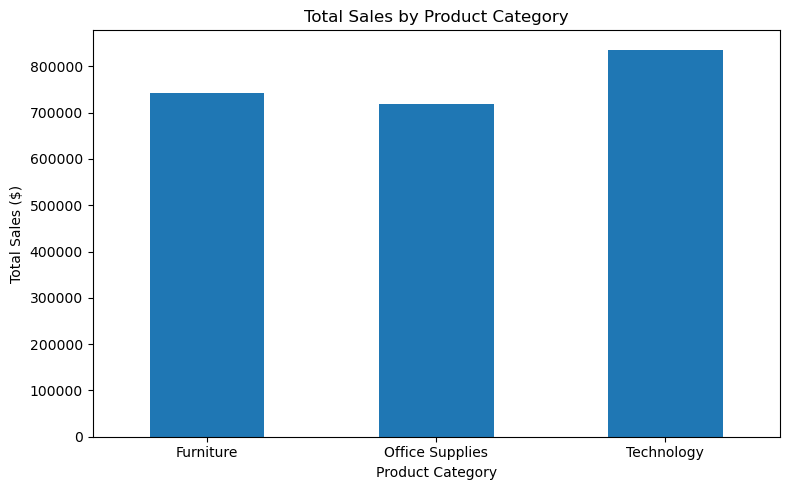

In [ ]:

category_sales = df_clean.groupby("Category")["Sales"].sum()


plt.figure(figsize=(8, 5))
category_sales.plot(kind="bar")


plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=0)


plt.tight_layout()
plt.show()

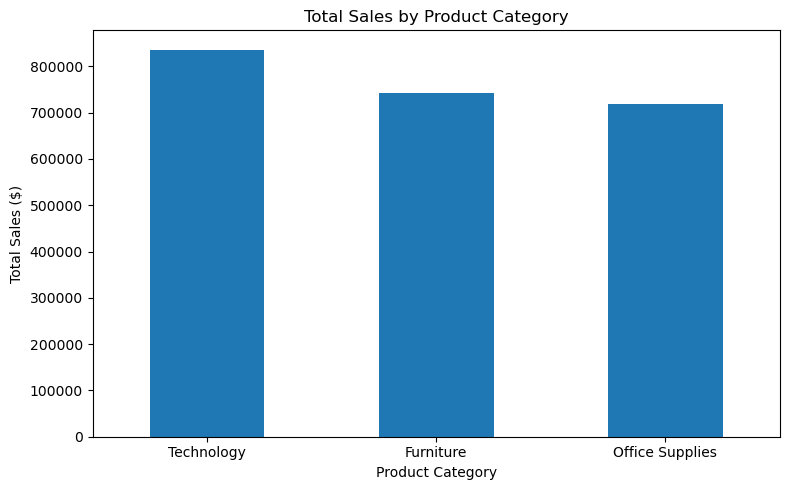

In [45]:
from pathlib import Path

output_folder = Path.cwd().parent / "visualizations"
output_folder.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 5))
category_sales.sort_values(ascending=False).plot(kind="bar")

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    output_folder / "sales_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [46]:

monthly_data = df_clean.copy()


monthly_data["Year_Month"] = (
    monthly_data["Order Date"].dt.to_period("M")
)

monthly_sales = (
    monthly_data.groupby("Year_Month")["Sales"]
    .sum()
    .sort_index()
)

display(monthly_sales)

Year_Month
2014-01     14236.8950
2014-02      4519.8920
2014-03     55691.0090
2014-04     28295.3450
2014-05     23648.2870
2014-06     34595.1276
2014-07     33946.3930
2014-08     27909.4685
2014-09     81777.3508
2014-10     31453.3930
2014-11     78628.7167
2014-12     69545.6205
2015-01     18174.0756
2015-02     11951.4110
2015-03     38726.2520
2015-04     34195.2085
2015-05     30131.6865
2015-06     24797.2920
2015-07     28765.3250
2015-08     36898.3322
2015-09     64595.9180
2015-10     31404.9235
2015-11     75972.5635
2015-12     74919.5212
2016-01     18542.4910
2016-02     22978.8150
2016-03     51715.8750
2016-04     38750.0390
2016-05     56987.7280
2016-06     40344.5340
2016-07     39261.9630
2016-08     31115.3743
2016-09     73410.0249
2016-10     59687.7450
2016-11     79411.9658
2016-12     96999.0430
2017-01     43971.3740
2017-02     20301.1334
2017-03     58872.3528
2017-04     36521.5361
2017-05     44261.1102
2017-06     52981.7257
2017-07     45264.4160


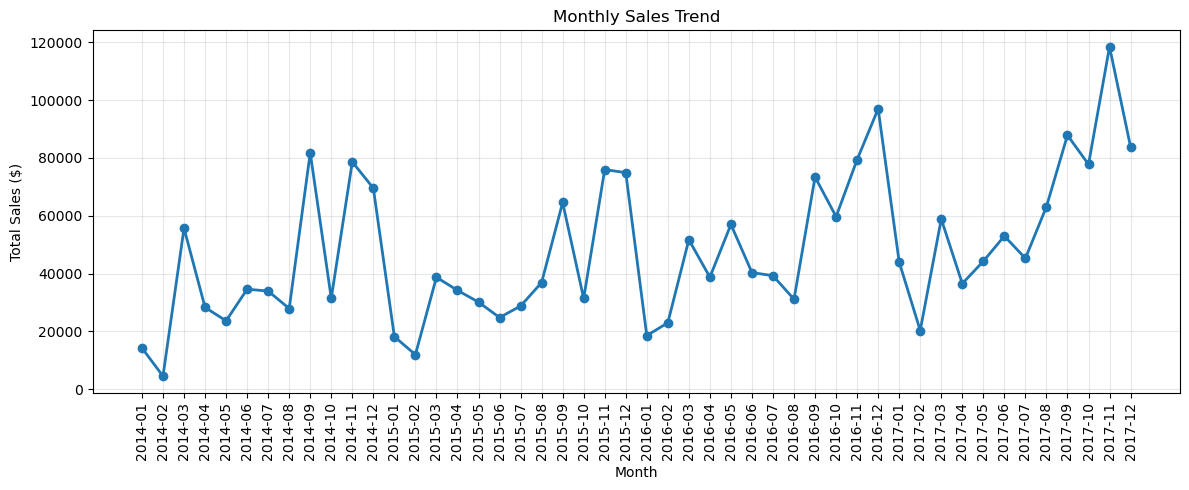

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [48]:
best_month = monthly_sales.idxmax()
worst_month = monthly_sales.idxmin()

print("Highest sales month:", best_month)
print(f"Highest monthly sales: ${monthly_sales.max():,.2f}")

print("\nLowest sales month:", worst_month)
print(f"Lowest monthly sales: ${monthly_sales.min():,.2f}")

Highest sales month: 2017-11
Highest monthly sales: $118,447.82

Lowest sales month: 2014-02
Lowest monthly sales: $4,519.89


In [49]:
subcategory_analysis = (
    df_clean.groupby("Sub-Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .sort_values("Total_Profit", ascending=False)
)

display(subcategory_analysis.round(2))

,Total_Sales,Total_Profit,Total_Quantity
Sub-Category,,,
Copiers,149528.03,55617.82,234
Phones,330007.05,44515.73,3289
Accessories,167380.32,41936.64,2976
Paper,78479.21,34053.57,5178
Binders,203412.73,30221.76,5974
Chairs,328449.10,26590.17,2356
Storage,223843.61,21278.83,3158
Appliances,107532.16,18138.01,1729
Furnishings,91705.16,13059.14,3563


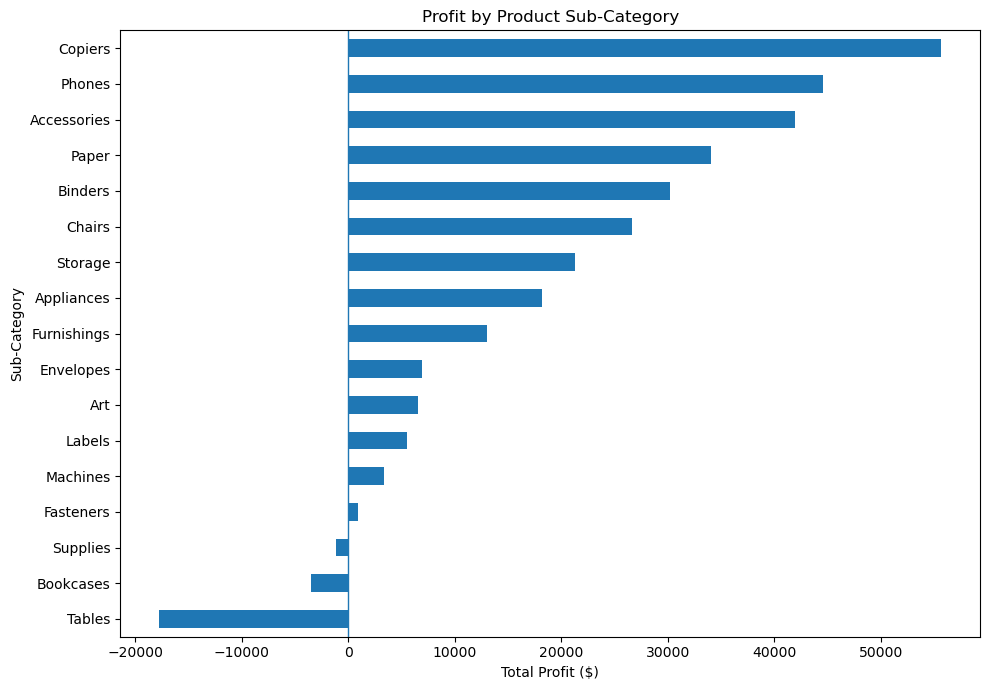

In [50]:
import matplotlib.pyplot as plt

profit_by_subcategory = subcategory_analysis["Total_Profit"].sort_values()

plt.figure(figsize=(10, 7))

profit_by_subcategory.plot(kind="barh")

plt.title("Profit by Product Sub-Category")
plt.xlabel("Total Profit ($)")
plt.ylabel("Sub-Category")
plt.axvline(0, linewidth=1)
plt.tight_layout()
plt.show()

In [51]:
best = subcategory_analysis["Total_Profit"].idxmax()
worst = subcategory_analysis["Total_Profit"].idxmin()

print("Most profitable sub-category:", best)
print(f"Profit: ${subcategory_analysis.loc[best, 'Total_Profit']:,.2f}")

print("\nLeast profitable sub-category:", worst)
print(f"Profit: ${subcategory_analysis.loc[worst, 'Total_Profit']:,.2f}")

Most profitable sub-category: Copiers
Profit: $55,617.82

Least profitable sub-category: Tables
Profit: $-17,725.48


In [52]:
subcategory_analysis["Profit_Margin_%"] = (
    subcategory_analysis["Total_Profit"]
    / subcategory_analysis["Total_Sales"]
    * 100
)

display(
    subcategory_analysis.sort_values(
        "Profit_Margin_%", ascending=False
    ).round(2)
)

,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin_%
Sub-Category,,,,
Labels,12486.31,5546.25,1400,44.42
Paper,78479.21,34053.57,5178,43.39
Envelopes,16476.40,6964.18,906,42.27
Copiers,149528.03,55617.82,234,37.20
Fasteners,3024.28,949.52,914,31.40
Accessories,167380.32,41936.64,2976,25.05
Art,27118.79,6527.79,3000,24.07
Appliances,107532.16,18138.01,1729,16.87
Binders,203412.73,30221.76,5974,14.86


In [53]:
discount_analysis = (
    df_clean.groupby("Discount")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Order_Count=("Order ID", "nunique")
    )
    .sort_index()
)

display(discount_analysis.round(2))

,Total_Sales,Total_Profit,Order_Count
Discount,,,
0.00,1087908.47,320987.60,2644
0.10,54369.35,9029.18,89
0.15,27558.52,1418.99,51
0.20,764594.37,90337.31,2407
0.30,103226.66,-10369.28,211
0.32,14493.46,-2391.14,27
0.40,116417.78,-23057.05,185
0.45,5484.97,-2493.11,10
0.50,58918.54,-20506.43,64


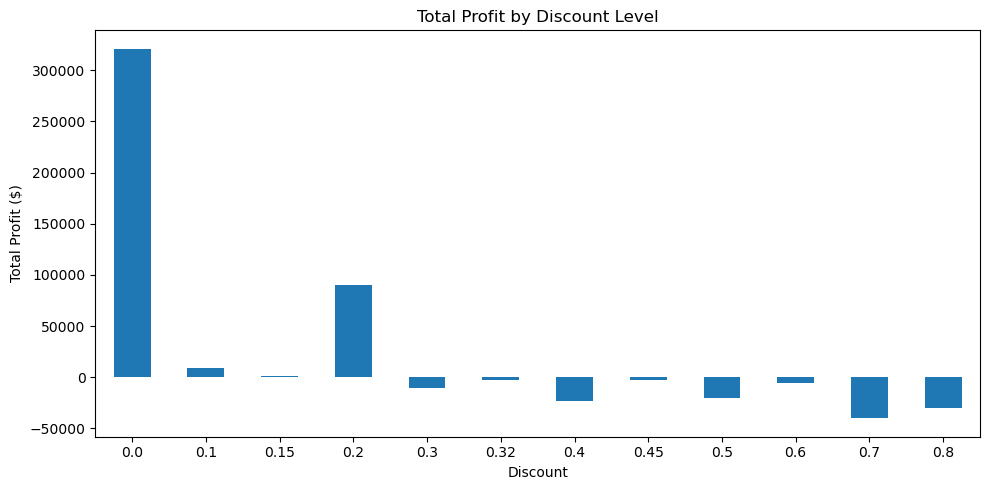

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

discount_analysis["Total_Profit"].plot(
    kind="bar",
    rot=0
)

plt.title("Total Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Total Profit ($)")
plt.tight_layout()
plt.show()

In [55]:
kpis = {
    "Total Sales": df_clean["Sales"].sum(),
    "Total Profit": df_clean["Profit"].sum(),
    "Total Orders": df_clean["Order ID"].nunique(),
    "Total Customers": df_clean["Customer ID"].nunique(),
    "Total Products": df_clean["Product ID"].nunique(),
    "Average Order Value": (
        df_clean["Sales"].sum()
        / df_clean["Order ID"].nunique()
    ),
    "Overall Profit Margin (%)": (
        df_clean["Profit"].sum()
        / df_clean["Sales"].sum()
        * 100
    )
}

for metric, value in kpis.items():
    print(f"{metric}: {value:,.2f}")

Total Sales: 2,297,200.86
Total Profit: 286,397.02
Total Orders: 5,009.00
Total Customers: 793.00
Total Products: 1,862.00
Average Order Value: 458.61
Overall Profit Margin (%): 12.47


In [57]:

category_sales = df_clean.groupby("Category")["Sales"].sum()
print("Highest-sales category:", category_sales.idxmax())


region_profit = df_clean.groupby("Region")["Profit"].sum()
print("Most profitable region:", region_profit.idxmax())


subcategory_profit = df_clean.groupby("Sub-Category")["Profit"].sum()
print("Most profitable sub-category:", subcategory_profit.idxmax())
print("Least profitable sub-category:", subcategory_profit.idxmin())


monthly_sales = (
    df_clean.assign(
        Year_Month=df_clean["Order Date"].dt.to_period("M")
    )
    .groupby("Year_Month")["Sales"]
    .sum()
)
print("Best sales month:", monthly_sales.idxmax())

Highest-sales category: Technology
Most profitable region: West
Most profitable sub-category: Copiers
Least profitable sub-category: Tables
Best sales month: 2017-11


In [58]:
print("SUPERSTORE SALES ANALYSIS")
print("=" * 40)

print(f"Total Sales: ${kpis['Total Sales']:,.2f}")
print(f"Total Profit: ${kpis['Total Profit']:,.2f}")
print(f"Total Orders: {kpis['Total Orders']:,}")
print(f"Total Customers: {kpis['Total Customers']:,}")
print(f"Average Order Value: ${kpis['Average Order Value']:,.2f}")
print(f"Profit Margin: {kpis['Overall Profit Margin (%)']:.2f}%")

print("=" * 40)
print("Analysis completed successfully!")

SUPERSTORE SALES ANALYSIS
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5,009
Total Customers: 793
Average Order Value: $458.61
Profit Margin: 12.47%
Analysis completed successfully!


In [59]:
from pathlib import Path

reports_folder = project_folder / "reports"
charts_folder = project_folder / "visualizations"

reports_folder.mkdir(parents=True, exist_ok=True)
charts_folder.mkdir(parents=True, exist_ok=True)

print("Output folders are ready!")

Output folders are ready!


In [60]:
category_sales.to_csv(
    reports_folder / "category_sales.csv",
    header=True
)

region_performance.to_csv(
    reports_folder / "region_performance.csv"
)

subcategory_analysis.to_csv(
    reports_folder / "subcategory_profitability.csv"
)

monthly_sales.to_csv(
    reports_folder / "monthly_sales.csv"
)

discount_analysis.to_csv(
    reports_folder / "discount_analysis.csv"
)

print("Analysis tables exported successfully!")

Analysis tables exported successfully!


In [61]:
df_clean.to_csv(
    reports_folder / "cleaned_superstore.csv",
    index=False
)